# 2. Data Quality Audit

The initial exploration identified 9357 observations, 114 additional empty rows and two empty columns. Missing measurements are encoded as -200 and no duplicate observations were found.

The selected regression target is NO2(GT), using five sensor responses and three environmental variables as input features.

# Duplicates
Repeated measurements at different timestamps are considered valid observations, even if their sensor values are similar. These observations are retained.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load and preserve original dataset
df_original = pd.read_csv("../data/AirQualityUCI.csv", sep=";", decimal=",")

## 1. Data cleaning - empty rows and columns

Completely empty rows and columns are removed because they contain no useful information. Partially missing observations are retained for further investigation.

In [2]:
df = df_original.dropna(how="all")
df = df.dropna(axis=1, how="all")

df.shape

(9357, 15)

## 2. Additional data quality checks

Data types and unique values are examined to identify potential inconsistencies and uninformative columns.

In [3]:
# Inspect data types and non-missing values
df.info()

# Count unique values per column
df.nunique().sort_values()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), str(2)
memory usage: 1.1 MB


Time               24
CO(GT)             97
NO2(GT)           284
Date              391
C6H6(GT)          408
NMHC(GT)          430
T                 437
RH                754
NOx(GT)           926
PT08.S1(CO)      1042
PT08.S3(NOx)     1222
PT08.S2(NMHC)    1246
PT08.S4(NO2)     1604
PT08.S5(O3)      1744
AH               6684
dtype: int64

## 3. Missing values

Missing measurements are encoded as -200 in the original dataset. These values are converted to NaN to enable correct missing-value analysis.

In [4]:
df = df.replace(-200, np.nan)
df.isna().sum()

Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

In [5]:
# Check missing values in the selected features
features = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S3(NOx)", 
            "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"
]

## Count rows with at least one missing feature
df[features].isna().any(axis=1).sum()

np.int64(366)

In [6]:
# Check available target value and complete feature rows
target = "NO2(GT)"

print("Valid target rows:", df[target].notna().sum())
print("Complete feature rows:", df[features].notna().all(axis=1).sum())
print("Rows with valid target and complete features:", (df[target].notna() & df[features].notna().all(axis=1)).sum())

Valid target rows: 7715
Complete feature rows: 8991
Rows with valid target and complete features: 7393


In [7]:
print("Missing dates:", df["Date"].isna().sum())
print("Missing times:", df["Time"].isna().sum())

print("Duplicate timestamps:", df.duplicated(subset=["Date", "Time"]).sum())

print("First timestamp:", df[["Date", "Time"]].iloc[0].to_dict())
print("Last timestamp:", df[["Date", "Time"]].iloc[-1].to_dict())


Missing dates: 0
Missing times: 0
Duplicate timestamps: 0
First timestamp: {'Date': '10/03/2004', 'Time': '18.00.00'}
Last timestamp: {'Date': '04/04/2005', 'Time': '14.00.00'}


In [8]:
timestamps = pd.to_datetime(
    df["Date"]+" "+df["Time"],
    format="%d/%m/%Y %H.%M.%S"
)

print("Chronologically sorted:", timestamps.is_monotonic_increasing)
print("Misssing hourly timestamps:", len(pd.date_range(timestamps.min(), timestamps.max(), freq="h").difference(timestamps)))

Chronologically sorted: True
Misssing hourly timestamps: 0


**Timestamp Audit**

Date and time were checked for missing values, duplicate timestamps, chronological order and hourly continuity. No issues were detected: all timestamps are unique, chronologically ordered and form a continuous hourly sequence from 10 March 2004 to 4 April 2005. Date and Time are retained for potential temporal feature engineering.

## 4. Chronological train-test split

The dataset contains hourly measurements ordered by time. To avoid temporal leakage, the first 80% of observations will be used for training and the remaining 20% for testing.

The split is performed before fitting any data-dependent preprocessing steps.

In [9]:
# Split the observations chronologically (80% training, 20% test)
split_index = int(len(df)*0.8)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))


Training rows: 7485
Test rows: 1872


In [10]:
# Audit missing target values before excluding any rows
print("Total rows:", len(df))
print("Missing target values:", df[target].isna().sum())
print("Missing target percentage:", round(df[target].isna().mean()*100, 1))

print("\nMissing target percentage by split:")
print("Training:",  round(df.iloc[:split_index][target].isna().mean()*100, 1))
print("Test:",  round(df.iloc[split_index:][target].isna().mean()*100, 1))

Total rows: 9357
Missing target values: 1642
Missing target percentage: 17.5

Missing target percentage by split:
Training: 21.2
Test: 3.1


In [11]:
# Investigate consecutive missing target value
missing_target = df[target].isna()

groups = missing_target.ne(missing_target.shift()).cumsum()
missing_runs = missing_target.groupby(groups).sum()
missing_runs = missing_runs[missing_runs > 0]

print("Number of missing-value periods:", len(missing_runs))
print("Longest mising-value period (hours):", missing_runs.max())
print("Median mising-value period (hours):", missing_runs.median())


Number of missing-value periods: 344
Longest mising-value period (hours): 173
Median mising-value period (hours): 1.0


In [12]:
# Check whether missing target values coincide with missing sensor values
missing_features = df[features].isna().any(axis=1)

print("Missing target with missing features:", (missing_target & missing_features).sum())
print("Missing target with complete features:", (missing_target & ~missing_features).sum())

Missing target with missing features: 44
Missing target with complete features: 1598


 **Missing target values - decision**

 The audit identified 1,642 missing NO2(GT) values (17.5%). These occur in 344 separate periods, with the longest lasting 173 hours. In 1,598 cases, all selected input features are available, but the target is missing.

 Rows with missing targets are excluded from training and test evaluation because supervised regression requires known target values. Mean or median imputation would create artificial labels and potentially distort the results.

In [13]:
# Remove rows without a known target value
train_df = train_df.dropna(subset=["NO2(GT)"]).copy()
test_df = test_df.dropna(subset=["NO2(GT)"]).copy()

print("Training rows with valid target:", len(train_df))
print("Test rows with valid target:", len(test_df))


Training rows with valid target: 5901
Test rows with valid target: 1814


## 5. Invalid values and outliers

Numerical variables are examined for suspicious ranges and potential outliers before deciding whether any values require treatment.

In [14]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
CO(GT),5528.0,2.273607,1.476181,0.1000,1.20000,2.0000,3.00000,11.9000
PT08.S1(CO),5662.0,1116.418403,221.660755,647.0000,954.00000,1083.0000,1252.00000,2040.0000
NMHC(GT),877.0,225.808438,205.731587,7.0000,73.00000,156.0000,304.00000,1189.0000
C6H6(GT),5662.0,11.086418,7.551867,0.2000,5.42500,9.4000,15.10000,63.7000
PT08.S2(NMHC),5662.0,979.475627,262.352568,397.0000,786.00000,955.5000,1152.00000,2214.0000
NOx(GT),5901.0,229.186917,210.938382,2.0000,86.00000,159.0000,300.00000,1479.0000
PT08.S3(NOx),5662.0,839.234193,260.822277,322.0000,665.00000,800.0000,969.00000,2683.0000
NO2(GT),5901.0,103.642095,42.343671,2.0000,72.00000,101.0000,129.00000,288.0000
PT08.S4(NO2),5662.0,1552.539739,313.651776,682.0000,1346.00000,1545.0000,1744.00000,2775.0000
PT08.S5(O3),5662.0,1051.475274,391.901293,261.0000,768.00000,996.0000,1305.00000,2523.0000


In [15]:
numeric_cols = train_df.select_dtypes(include="number").columns

Q1 = train_df[numeric_cols].quantile(0.25)
Q3 = train_df[numeric_cols].quantile(0.75)
IQR = Q3-Q1

The 1.5xIQR rule was chosen as a simple, robust method for identifying potential outliers without assuming a normal distribution. Flagged values are not automatically removed.

In [16]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (
    (train_df[numeric_cols] < lower_bound) |
    (train_df[numeric_cols] > upper_bound) 
)

outliers_summary = pd.DataFrame({
    "Q1 (25%)": Q1,
    "Q3 (75%)": Q3,
    "IQR": IQR,
    "Lower bound": lower_bound,
    "Upper_bound": upper_bound,
    "Potential Outliers": outliers.sum()
})

outliers_summary

,Q1 (25%),Q3 (75%),IQR,Lower bound,Upper_bound,Potential Outliers
CO(GT),1.20000,3.00000,1.800,-1.50000,5.70000,157
PT08.S1(CO),954.00000,1252.00000,298.000,507.00000,1699.00000,77
NMHC(GT),73.00000,304.00000,231.000,-273.50000,650.50000,53
C6H6(GT),5.42500,15.10000,9.675,-9.08750,29.61250,141
PT08.S2(NMHC),786.00000,1152.00000,366.000,237.00000,1701.00000,41
NOx(GT),86.00000,300.00000,214.000,-235.00000,621.00000,366
PT08.S3(NOx),665.00000,969.00000,304.000,209.00000,1425.00000,169
NO2(GT),72.00000,129.00000,57.000,-13.50000,214.50000,63
PT08.S4(NO2),1346.00000,1744.00000,398.000,749.00000,2341.00000,90
PT08.S5(O3),768.00000,1305.00000,537.000,-37.50000,2110.50000,51


In [17]:
no2_outliers = train_df.loc[outliers["NO2(GT)"], "NO2(GT)"]

print("Number of potential outliers:", len(no2_outliers))
print("Minimum:", no2_outliers.min())
print("Maximum:", no2_outliers.max())

no2_outliers.describe()

Number of potential outliers: 63
Minimum: 215.0
Maximum: 288.0


count     63.000000
mean     234.809524
std       17.703524
min      215.000000
25%      220.500000
50%      231.000000
75%      242.500000
max      288.000000
Name: NO2(GT), dtype: float64

**Outlier investigation (IQR Method)**

Potential outliers were identified using the 1.5xIQR rule.
For the target NO2(GT), 63 potential outliers were detected, ranging from 215 to 288. All exceed the upper IQR threshold of 214.5.
These values may represent genuine periods of elevated air pollution rather than measurement errors. Therefore, they are retained at this stage. Further investigation may be needed before applying any outlier treatment.


In [18]:
train_df[features].agg(["min","max"]).T

,min,max
PT08.S1(CO),647.0000,2040.0000
PT08.S2(NMHC),397.0000,2214.0000
PT08.S3(NOx),322.0000,2683.0000
PT08.S4(NO2),682.0000,2775.0000
PT08.S5(O3),261.0000,2523.0000
T,1.2000,44.6000
RH,9.2000,88.7000
AH,0.1988,2.1806


**Feature Outlier Assessment**

The eight input features were checked for invalid values and potential outliers. No obviously invalid values were identified. Extreme sensor readings were retained, as they may represent genuine measurements.

## 6. Target distribution

In [19]:
train_df[target].describe()

count    5901.000000
mean      103.642095
std        42.343671
min         2.000000
25%        72.000000
50%       101.000000
75%       129.000000
max       288.000000
Name: NO2(GT), dtype: float64

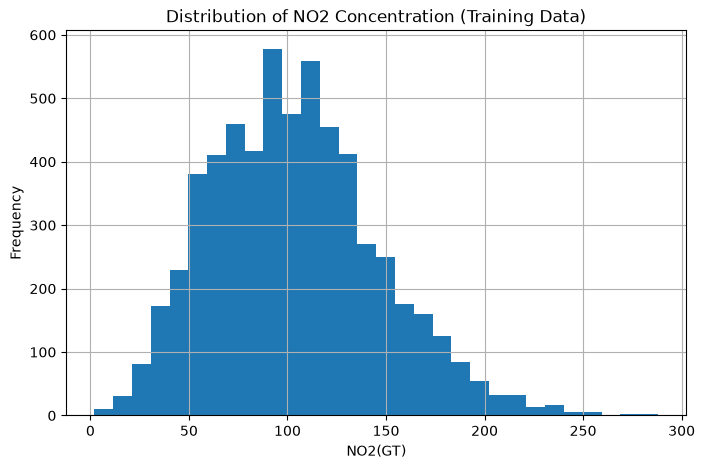

In [20]:
train_df[target].hist(bins=30, figsize=(8, 5))

plt.title("Distribution of NO2 Concentration (Training Data)")
plt.xlabel("NO2(GT)")
plt.ylabel("Frequency")
plt.show()

**Target distribution - interpretation**

The training target contains 5,901 valid NO2 observations. The distribution is unimodal and slightly right-skewed, with a mean of 103.64 and a median of 101.

Most observations are concentrated around the centre of the distribution, while a smaller number of high values extend the right tail. These observations are retained, as previously justified in the outlier assessment.
